# UTS Graf Sains Data - Python Driver Neo4j & Rekomendasi (RetailRocket)

**Nama:** Alamsyah Ramadhan Vaganza &nbsp;&nbsp; **NIM:** 23031554192 &nbsp;&nbsp; **Kelas:** 2023B 

## 1. Tugas Pendahuluan
### 1.1 Persiapan dan Perkenalan Lingkungan

Jalankan di terminal (bukan di notebook):

```bash
uv venv myvenv --python 3.10        # atau: python -m venv myvenv
conda deactivate                    # bila ada env conda aktif
source myvenv/bin/activate          # Windows: myvenv\Scripts\activate
uv pip install -r requirements.txt
```

In [1]:
%%writefile requirements.txt
neo4j>=5.8
pandas>=2.0
numpy
scipy
scikit-learn
networkx>=3.0
matplotlib
tqdm

Writing requirements.txt


In [2]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Konfigurasi global
Semua parameter yang perlu disesuaikan dikumpulkan di satu sel.

In [ ]:
import os, sys, time, zipfile, argparse, subprocess
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from neo4j import GraphDatabase, RoutingControl, Result
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

# ---- Koneksi Neo4j 
URI  = os.getenv("NEO4J_URI", "neo4j://127.0.0.1:7687")
AUTH = (os.getenv("NEO4J_USER", "neo4j"), os.getenv("NEO4J_PASSWORD", "sayaadalahadmin"))
DB   = "neo4j"

# ---- Data & periode 
DATA_DIR     = "data"
FILTERED_CSV = os.path.join(DATA_DIR, "events_filtered.csv")
P1 = ("2015-06-01", "2015-08-01")   
P2 = ("2015-08-10", "2015-08-25")   
SEED = 23031554192                  
# ---- Bobot interaksi untuk VSM
W   = {"view": 1, "addtocart": 3, "transaction": 5}
REL = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}

SEED32 = SEED % 2**32              
np.random.seed(SEED32)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ---- Gaya visualisasi (palet konsisten di seluruh notebook) ----
C_USER, C_ITEM, C_BUY, C_REF = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"   # Visitor/P1, Item/P2, transaksi/relevan, acuan/target
C_INK, C_MUTED = "#52514e", "#898781"
C_FOLD = {"P1": C_USER, "P2": C_ITEM}
C_EVENT = {"view": C_USER, "addtocart": C_ITEM, "transaction": C_BUY}
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": C_MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 11, "axes.labelcolor": C_INK,
    "xtick.color": C_INK, "ytick.color": C_INK, "legend.frameon": False,
})

def bar_labels(ax, bars, fmt="{:,.0f}", **kw):
    for b in bars:
        v = b.get_width() if kw.get("horizontal") else b.get_height()
        if kw.get("horizontal"):
            ax.annotate(fmt.format(v), (v, b.get_y() + b.get_height() / 2), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=8, color=C_INK)
        else:
            ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                        textcoords="offset points", ha="center", fontsize=8, color=C_INK)

### 1.2 Mempelajari Penggunaan Driver Neo4j
Tutorial dari soal: koneksi, membuat node `Person` + relasi `KNOWS` dengan `MERGE`, lalu membaca kembali dengan `execute_query`.

In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as drv:
    for f in ["Guinevere", "Lancelot", "Merlin"]:
        add_friend(drv, "Arthur", f)
    print_friends(drv, "Arthur")

Guinevere
Lancelot
Merlin


#### Jawaban Pertanyaan Pendahuluan (*Checkpoint*)

1. **Nama database:** `neo4j` — ditentukan lewat argumen `database_="neo4j"` pada setiap `execute_query` (database default Neo4j).
2. **Akses ke database lain dalam 1 instance:**
   - Di driver: ganti parameter `database_="namadb"` atau `driver.session(database="namadb")`.
   - Cypher: klausa `USE namadb MATCH (n) RETURN n` (Neo4j 4.x+), dan di Neo4j Browser/cypher-shell perintah `:use namadb`.
   - DDL administrasi (dijalankan pada database `system`): `SHOW DATABASES`, `CREATE DATABASE namadb`, `STOP/START DATABASE namadb`, `DROP DATABASE namadb` (CREATE/DROP hanya di Enterprise Edition).
3. **Jenis graf pertemanan:** graf **berarah** (*directed*) dan **tak berbobot** dengan satu tipe relasi `KNOWS`. Strukturnya berbentuk **star graph / out-tree**: simpul pusat `Arthur` memiliki out-degree 3 menuju `Guinevere`, `Lancelot`, `Merlin` (masing-masing in-degree 1). `MERGE` menjamin tidak ada node/relasi ganda jika sel dijalankan ulang.

#### CYPHER Total Reset
Untuk database besar, `MATCH (n) DETACH DELETE n` dalam satu transaksi bisa kehabisan memori, jadi penghapusan dipecah per 10.000 baris (`CALL (n) { ... } IN TRANSACTIONS`, sintaks Neo4j 5.23+, wajib lewat *auto-commit session*). ⚠️ Hati-hati pada *shared database*.

In [4]:
driver = GraphDatabase.driver(URI, auth=AUTH, notifications_min_severity="OFF")  # sembunyikan warning info DBMS
driver.verify_connectivity()

def q(cypher, write=False, **params):
    # Helper: jalankan Cypher, kembalikan hasil sebagai DataFrame.
    return driver.execute_query(
        cypher, params, database_=DB,
        routing_=RoutingControl.WRITE if write else RoutingControl.READ,
        result_transformer_=Result.to_df,
    )

def reset_db():
    with driver.session(database=DB) as s:
        s.run("MATCH (n) CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS").consume()

reset_db()
q("MATCH (n) RETURN count(n) AS sisa_node")

,sisa_node
0,0


### 1.3 Impor Data RetailRocket ke Neo4j
Sumber data: *Roman Zykov* (Kaggle `retailrocket/ecommerce-dataset`). Fitur `events.csv`:

| Kolom | Keterangan |
|---|---|
| `timestamp` | waktu (unix epoch, **milidetik**) |
| `visitorid` | ID unik pengunjung |
| `event` | `view`, `addtocart`, `transaction` |
| `itemid` | ID unik produk |
| `transactionid` | ID transaksi, hanya terisi saat `event = transaction` |

**1. Unduh data** 

In [5]:
import os
DATA_DIR = "data"
ZIP = "ecommerce-dataset.zip"
URL = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"
os.makedirs(DATA_DIR, exist_ok=True)

if not os.path.exists(os.path.join(DATA_DIR, "events.csv")):
    if not os.path.exists(ZIP):
        subprocess.run(["curl", "-L", "-o", ZIP, URL], check=True)
    with zipfile.ZipFile(ZIP) as z:
        z.extract("events.csv", DATA_DIR)
os.listdir(DATA_DIR)

['events.csv', 'events_filtered.csv']

**3. Argumen koneksi (argparse).** Di notebook `parse_args([])` dipakai agar nilai default terbaca; skrip yang sama bisa dijalankan dari terminal.

In [6]:
def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(description="Impor dataset RetailRocket (events.csv) ke database Neo4j.")
    parser.add_argument("-u", "--user",     default=AUTH[0], help="Username Neo4j")
    parser.add_argument("-p", "--password", default=AUTH[1], help="Password Neo4j")
    parser.add_argument("-b", "--bolt",     default=URI,     help="Neo4j URI / Bolt")
    parser.add_argument("-s", "--source",   default=DATA_DIR, help="Direktori sumber data")
    parser.add_argument("-n", "--batch",    type=int, default=10_000, help="Ukuran batch")
    return parser.parse_args(argv)

args = parse_arguments([])
args

Namespace(user='neo4j', password='sayaadalahadmin', bolt='neo4j://127.0.0.1:7687', source='data', batch=10000)

**4–5. Fungsi impor batch.** Template soal memakai satu query `CALL { ... UNION ALL ... }`. Di sini setiap batch dipecah per jenis event di Python, lalu tiap jenis dijalankan dengan `UNWIND` + `CREATE` relasi bertipe tetap. Hasil graf identik, tetapi query lebih sederhana dan tidak bergantung pada sintaks subquery yang berbeda antar versi Neo4j. Semua sub-batch tetap berada dalam **satu transaksi** (`execute_write`).

Skema graf: `(:Visitor {visitorId})-[:VIEWED|ADDED_TO_CART|BOUGHT {timestamp, fold}]->(:Item {itemId})`. Properti `fold` (`P1`/`P2`) menandai periode.

In [7]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    for ev_type, rel in REL.items():
        rows = [r for r in batch if r["event"] == ev_type]
        if not rows:
            continue
        extra = ", transactionId: row.transactionid" if rel == "BOUGHT" else ""
        tx.run(f'''
            UNWIND $rows AS row
            MERGE (v:Visitor {{visitorId: row.visitorid}})
            MERGE (i:Item    {{itemId:    row.itemid}})
            CREATE (v)-[:{rel} {{timestamp: row.timestamp, fold: row.fold{extra}}}]->(i)
        ''', rows=rows)

def run_import(csv_file_path, batch_size):
    if not os.path.exists(csv_file_path):
        sys.exit(f"Error: File '{csv_file_path}' tidak ditemukan!")
    total_rows = sum(1 for _ in open(csv_file_path)) - 1
    total_chunks = -(-total_rows // batch_size)
    with driver.session(database=DB) as session:
        create_constraints(session)
        print(f"Membaca {total_rows:,} baris dari: {csv_file_path}")
        for chunk in tqdm(pd.read_csv(csv_file_path, chunksize=batch_size),
                          total=total_chunks, desc="Mengimpor Batch Data"):
            chunk["transactionid"] = chunk["transactionid"].fillna(-1).astype("int64")
            session.execute_write(import_batch, chunk.to_dict(orient="records"))
    print("Proses impor berhasil.")

## 2. Soal UTS
### 2.1 Wrangling dan EDA

#### No. 1 -  Penentuan 2 periode waktu

| Fold | Mulai | Hingga |
|---|---|---|
| Training (P1) | 01/06/2015 | 01/08/2015 |
| Testing (P2) | 10/08/2015 | 25/08/2015 |

Tanggal *hingga* diperlakukan **inklusif** (sampai 23:59:59.999 hari itu). Ada jeda 02/08–09/08 yang tidak dipakai, sehingga P1 dan P2 tidak beririsan.

Cek dulu rentang waktu data agar periode yang dipilih valid.

In [8]:
ev = pd.read_csv(os.path.join(DATA_DIR, "events.csv"),
                 dtype={"visitorid": "int64", "itemid": "int64", "event": "category"})
ev["dt"] = pd.to_datetime(ev["timestamp"], unit="ms")   # UTC
print(f"Total event : {len(ev):,}")
print(f"Rentang data: {ev.dt.min()}  s.d.  {ev.dt.max()}")
ev.groupby(ev.dt.dt.to_period("M"))["event"].value_counts().unstack()

Total event : 2,756,101
Rentang data: 2015-05-03 03:00:04.384000  s.d.  2015-09-18 02:59:47.788000


event,addtocart,transaction,view
dt,,,
2015-05,14369,4611,571672
2015-06,15095,5043,590255
2015-07,17362,5802,674820
2015-08,14825,4632,533905
2015-09,7681,2369,293660


**Visualisasi No. 1 - Linimasa event harian dan posisi P1/P2.** Area biru = fold training, area oranye = fold testing, area abu-abu bergaris = jeda yang tidak dipakai. Sumbu-y kiri memakai skala log agar `addtocart` dan `transaction` tetap terlihat di samping `view`.

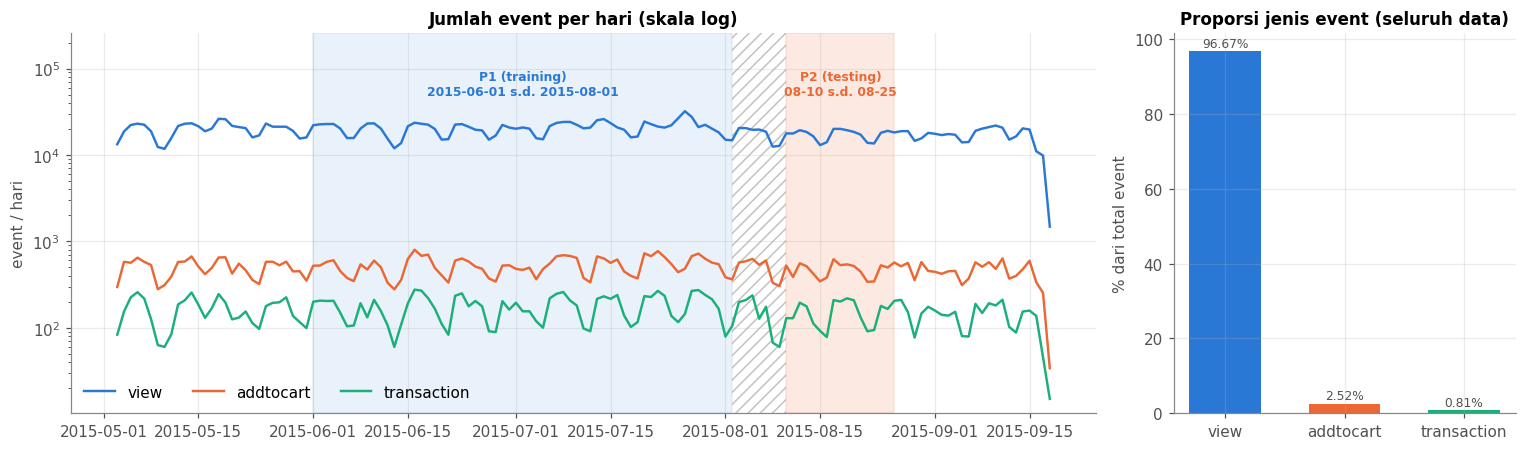

Rata-rata event/hari → P1: 21,352 | P2: 17,882 | seluruh data: 19,828
Hari tersibuk: 26 Jul 2015 (32,703 event) | tersepi: 18 Sep 2015 (1,528 event)


In [9]:
daily = ev.groupby([ev.dt.dt.floor("D"), "event"], observed=True).size().unstack(fill_value=0)
p1s, p1e = pd.Timestamp(P1[0]), pd.Timestamp(P1[1]) + pd.Timedelta(days=1)
p2s, p2e = pd.Timestamp(P2[0]), pd.Timestamp(P2[1]) + pd.Timedelta(days=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [3, 1]})
for e in ["view", "addtocart", "transaction"]:
    ax[0].plot(daily.index, daily[e], lw=1.6, color=C_EVENT[e], label=e)
ax[0].set_yscale("log")
ax[0].axvspan(p1s, p1e, color=C_USER, alpha=.10)
ax[0].axvspan(p1e, p2s, facecolor="none", edgecolor=C_MUTED, hatch="///", alpha=.5, lw=0)
ax[0].axvspan(p2s, p2e, color=C_ITEM, alpha=.14)
top = daily.values.max() * 3
ax[0].set_ylim(top=daily.values.max() * 8)
ax[0].text(p1s + (p1e - p1s) / 2, top, f"P1 (training)\n{P1[0]} s.d. {P1[1]}", ha="center", va="top", fontsize=8, color=C_USER, weight="bold")
ax[0].text(p2s + (p2e - p2s) / 2, top, f"P2 (testing)\n{P2[0][5:]} s.d. {P2[1][5:]}", ha="center", va="top", fontsize=8, color=C_ITEM, weight="bold")
ax[0].set(title="Jumlah event per hari (skala log)", ylabel="event / hari")
ax[0].legend(loc="lower left", ncol=3)

share = ev["event"].value_counts(normalize=True).reindex(["view", "addtocart", "transaction"]) * 100
b = ax[1].bar(share.index, share.values, color=[C_EVENT[e] for e in share.index], width=.6)
bar_labels(ax[1], b, "{:.2f}%")
ax[1].set(title="Proporsi jenis event (seluruh data)", ylabel="% dari total event")
plt.tight_layout(); plt.show()

tot = daily.sum(axis=1)
print(f"Rata-rata event/hari → P1: {tot[(tot.index >= p1s) & (tot.index < p1e)].mean():,.0f} | "
      f"P2: {tot[(tot.index >= p2s) & (tot.index < p2e)].mean():,.0f} | seluruh data: {tot.mean():,.0f}")
print(f"Hari tersibuk: {tot.idxmax():%d %b %Y} ({tot.max():,} event) | tersepi: {tot.idxmin():%d %b %Y} ({tot.min():,} event)")

**Interpretasi No. 1**
- Data mencakup **2.756.101 event** dari **3 Mei s.d. 18 Sep 2015**. Bulan Mei dan September tidak penuh (data mulai 3 Mei, berakhir 18 Sep), sehingga angka September (293.660 view) terlihat jauh lebih kecil.
- `view` mendominasi (**±96,7%**), `addtocart` hanya **±2,5%**, dan `transaction` **±0,8%**. Artinya sinyal pembelian sangat langka; tanpa pembobotan, interaksi `view` akan menenggelamkan `transaction`.
- Bulan **Juli** adalah puncak aktivitas (674.820 view, 17.362 addtocart, 5.802 transaksi).
- **P1** (1 Jun – 1 Agu 2015, 62 hari) memuat seluruh bulan Juni–Juli yang paling ramai, sehingga data latih cukup kaya. **P2** (10 – 25 Agu 2015, 16 hari) jauh lebih pendek. Jeda **2 – 9 Agu** (8 hari) tidak dipakai, sehingga tidak ada kebocoran informasi dari masa uji ke masa latih.
- Grafik harian dan angka rata-rata di atas menunjukkan level aktivitas harian P1 dan P2 sebanding, jadi perbedaan jumlah event antar-fold terutama disebabkan oleh **panjang periode**, bukan perubahan perilaku pengunjung.

#### No. 2 - Filter timestamp & simpan ke `.csv`
Filter dilakukan di pandas (vektorisasi, sekali baca) **sebelum** impor, sehingga Neo4j hanya menampung subgraf P1 ∪ P2. Batas akhir periode dibuat inklusif sampai 23:59:59.999. Baris duplikat persis dibuang.

In [10]:
def period_mask(p):
    start, end = pd.Timestamp(p[0]), pd.Timestamp(p[1]) + pd.Timedelta(days=1)
    return (ev.dt >= start) & (ev.dt < end)

m1, m2 = period_mask(P1), period_mask(P2)
assert not (m1 & m2).any(), "P1 dan P2 tidak boleh beririsan!"
assert m1.any() and m2.any(), "Periode kosong — pilih rentang di dalam data (2015)."

ev["fold"] = np.where(m1, "P1", np.where(m2, "P2", ""))
filt = ev.loc[ev.fold != "", ["timestamp", "visitorid", "event", "itemid", "transactionid", "fold"]].drop_duplicates()
filt.to_csv(FILTERED_CSV, index=False)

print(f"Tersimpan: {FILTERED_CSV} ({len(filt):,} baris, {os.path.getsize(FILTERED_CSV)/1e6:.1f} MB)")
filt.groupby("fold").agg(event=("event", "size"), visitor=("visitorid", "nunique"),
                         item=("itemid", "nunique")).join(
    pd.crosstab(filt.fold, filt.event.astype(str)))

Tersimpan: data\events_filtered.csv (1,609,654 baris, 61.5 MB)


,event,visitor,item,addtocart,transaction,view
fold,,,,,,
P1,1323616,684281,171044,32660,10924,1280032
P2,286038,164220,79628,7443,2410,276185


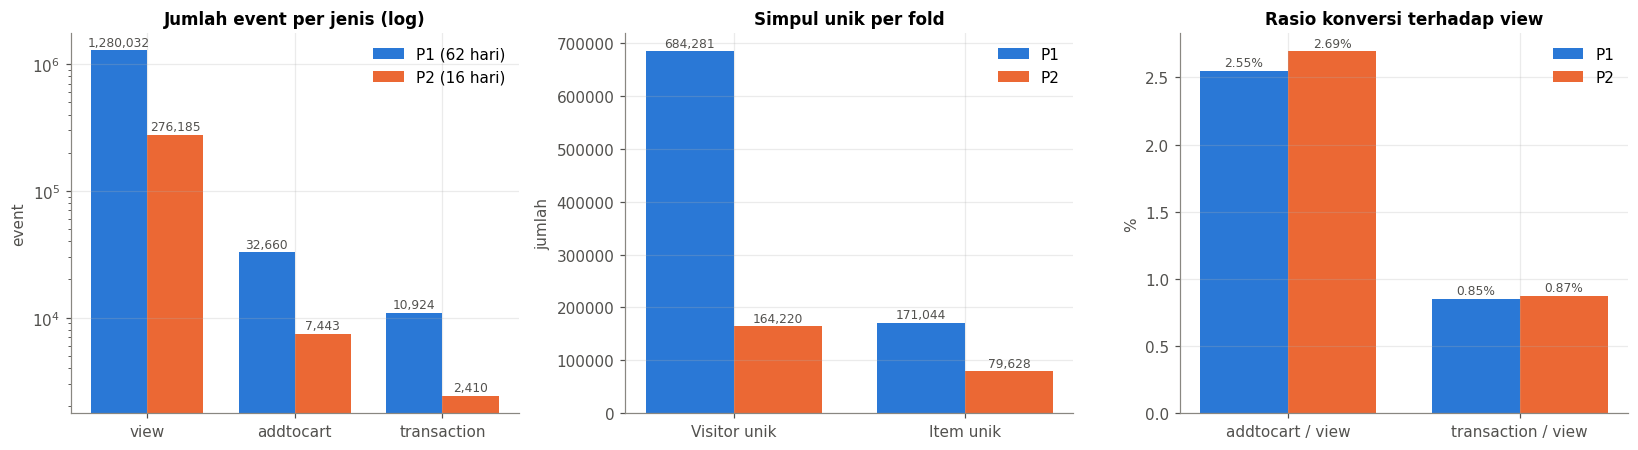

Event per hari: {'P1': '21,349', 'P2': '17,877'}


In [11]:
comp = pd.crosstab(filt.fold, filt.event.astype(str))[["view", "addtocart", "transaction"]]
uniq = filt.groupby("fold").agg(visitor=("visitorid", "nunique"), item=("itemid", "nunique"))
days = {"P1": (pd.Timestamp(P1[1]) - pd.Timestamp(P1[0])).days + 1, "P2": (pd.Timestamp(P2[1]) - pd.Timestamp(P2[0])).days + 1}

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(3); w = .38
for k, f in enumerate(["P1", "P2"]):
    b = ax[0].bar(x + (k - .5) * w, comp.loc[f], w, color=C_FOLD[f], label=f"{f} ({days[f]} hari)")
    bar_labels(ax[0], b)
ax[0].set(xticks=x, xticklabels=comp.columns, yscale="log", title="Jumlah event per jenis (log)", ylabel="event")
ax[0].legend()

x = np.arange(2)
for k, f in enumerate(["P1", "P2"]):
    b = ax[1].bar(x + (k - .5) * w, uniq.loc[f], w, color=C_FOLD[f], label=f)
    bar_labels(ax[1], b)
ax[1].set(xticks=x, xticklabels=["Visitor unik", "Item unik"], title="Simpul unik per fold", ylabel="jumlah")
ax[1].legend()

conv = comp[["addtocart", "transaction"]].div(comp["view"], axis=0) * 100
x = np.arange(2)
for k, f in enumerate(["P1", "P2"]):
    b = ax[2].bar(x + (k - .5) * w, conv.loc[f], w, color=C_FOLD[f], label=f)
    bar_labels(ax[2], b, "{:.2f}%")
ax[2].set(xticks=x, xticklabels=["addtocart / view", "transaction / view"], title="Rasio konversi terhadap view", ylabel="%")
ax[2].legend()
plt.tight_layout(); plt.show()

print("Event per hari:", {f: f"{comp.loc[f].sum() / days[f]:,.0f}" for f in comp.index})

**Interpretasi No. 2**
- Hasil filter menyimpan **1.609.654 baris (±58,4% dari seluruh data)** ke `events_filtered.csv` (61,5 MB).
- **P1** berisi **1.323.616 event** dari **684.281 visitor** dan **171.044 item**; **P2** berisi **286.038 event** dari **164.220 visitor** dan **79.628 item**. P1 ±4,6× lebih besar dari P2 karena periodenya ±3,9× lebih panjang (62 vs 16 hari).
- Rasio konversi kedua fold hampir sama: `addtocart/view` **2,55% (P1)** vs **2,69% (P2)**, `transaction/view` **0,85%** vs **0,87%**. Jadi distribusi perilaku pada data latih dan uji konsisten
- Di kedua fold jumlah visitor ±4× jumlah item (684 rb vs 171 rb di P1), petunjuk awal bahwa sisi Visitor jauh lebih besar dan lebih jarang (sparse) dibanding sisi Item.

In [12]:
del ev   # bebaskan memori
reset_db()
t0 = time.time()
run_import(FILTERED_CSV, args.batch)
print(f"Durasi impor: {time.time() - t0:.1f} detik")

Membaca 1,609,654 baris dari: data\events_filtered.csv


Mengimpor Batch Data: 100%|██████████| 161/161 [04:08<00:00,  1.54s/it]

Proses impor berhasil.
Durasi impor: 249.2 detik


#### No. 3 - Komposisi subgraf (Python API + Cypher)

| Query | Penjelasan |
|---|---|
| `MATCH (n:Visitor) RETURN count(n) ... UNION ALL ...` | Menghitung jumlah simpul per label. Pola `count(n)` pada satu label dijawab langsung dari *count store* Neo4j (tanpa scan), lalu digabung dengan `UNION ALL`. |
| `MATCH ()-[r]->() RETURN type(r), r.fold, count(*)` | Menghitung relasi per tipe (`VIEWED`/`ADDED_TO_CART`/`BOUGHT`) dan per fold. `type(r)` mengambil nama tipe relasi. |
| `MATCH (v:Visitor)-[r]->(i:Item) RETURN r.fold, count(DISTINCT v), count(DISTINCT i)` | Jumlah simpul unik yang aktif di tiap fold — inilah komposisi subgraf P1 dan P2. |

In [13]:
nodes = q('''
    MATCH (n:Visitor) RETURN 'Visitor' AS jenis_simpul, count(n) AS jumlah
    UNION ALL
    MATCH (n:Item)    RETURN 'Item'    AS jenis_simpul, count(n) AS jumlah
''')
rels = q('''
    MATCH ()-[r]->()
    RETURN type(r) AS relasi, r.fold AS fold, count(*) AS jumlah
    ORDER BY fold, jumlah DESC
''')
per_fold = q('''
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN r.fold AS fold, count(DISTINCT v) AS visitor, count(DISTINCT i) AS item, count(r) AS interaksi
    ORDER BY fold
''')
display(nodes, rels.pivot(index="relasi", columns="fold", values="jumlah"), per_fold)

,jenis_simpul,jumlah
0,Visitor,838210
1,Item,188060


fold,P1,P2
relasi,,
ADDED_TO_CART,32660,7443
BOUGHT,10924,2410
VIEWED,1280032,276185


,fold,visitor,item,interaksi
0,P1,684281,171044,1323616
1,P2,164220,79628,286038


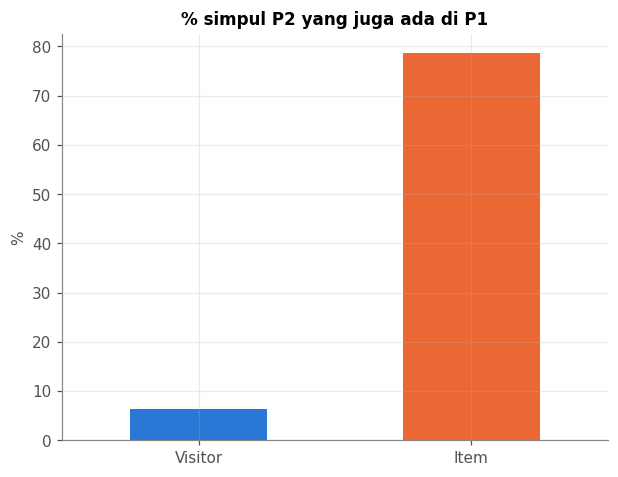

,P1 & P2,% dari P2
Visitor,10291,6.3
Item,62612,78.6


In [36]:
# Irisan simpul antara P1 dan P2
pf = per_fold.set_index("fold")
total = nodes.set_index("jenis_simpul").jumlah
both_v = pf.visitor.sum() - total["Visitor"]   # visitor yang muncul di P1 dan P2
both_i = pf.item.sum()    - total["Item"]      # item yang muncul di P1 dan P2

ov = pd.DataFrame({"P1 & P2": [both_v, both_i],
                   "% dari P2": [both_v / pf.visitor["P2"] * 100, both_i / pf.item["P2"] * 100]},
                  index=["Visitor", "Item"])
ov["% dari P2"].plot.bar(color=[C_USER, C_ITEM], rot=0, title="% simpul P2 yang juga ada di P1")
plt.ylabel("%"); plt.show()
ov.round(1)

**Interpretasi No. 3**
- Graf di Neo4j berisi **1.026.270 simpul** (**838.210 Visitor** + **188.060 Item**) dan **1.609.654 relasi** — sama persis dengan jumlah baris CSV, jadi impor lengkap tanpa baris hilang.
- Subgraf bersifat **bipartit berarah**: semua relasi mengarah dari `Visitor` ke `Item`, tidak ada relasi Visitor–Visitor maupun Item–Item. Karena itu kemiripan antar-user atau antar-item harus diperoleh lewat **proyeksi** (no. 4–6).
- Komposisi relasi sangat timpang: `VIEWED` **1.280.032** (P1) / **276.185** (P2), `ADDED_TO_CART` **32.660 / 7.443**, `BOUGHT` **10.924 / 2.410**. Ini alasan event diberi bobot **1 / 3 / 5** pada VSM.
- **Temuan penting (grafik irisan):** hanya **10.291 visitor (±6,3%)** dari 164.220 visitor P2 yang juga muncul di P1. Sebaliknya **62.612 item (±78,6%)** dari 79.628 item P2 sudah ada di P1. Jadi masalah utama dataset ini adalah **cold-start user**: sebagian besar pengunjung masa uji adalah pengunjung baru, sedangkan katalog item relatif stabil. Ini akan menjelaskan nilai Hit@5/NDCG@5 yang rendah di bagian 2.2.

#### Persiapan VSM: matriks interaksi berbobot dari Neo4j
Bobot tiap pasangan (visitor, item) = jumlah bobot semua event-nya pada fold tersebut, dihitung langsung di Cypher dengan `sum(CASE type(r) ...)`. Hasilnya disimpan sebagai matriks sparse CSR (hemat memori; matriks dense tidak mungkin dimuat).

In [16]:
def case_w(var):
    return "CASE type(%s) " % var + " ".join(f"WHEN '{REL[e]}' THEN {w}" for e, w in W.items()) + " END"

def load_interactions(fold):
    return q(f'''
        MATCH (v:Visitor)-[r]->(i:Item) WHERE r.fold = $fold
        RETURN v.visitorId AS u, i.itemId AS i, sum({case_w("r")}) AS w
    ''', fold=fold)

tr, te = load_interactions("P1"), load_interactions("P2")

u_codes, users = pd.factorize(tr.u)
i_codes, items = pd.factorize(tr.i)
users, items = np.asarray(users), np.asarray(items)
user_pos = pd.Series(np.arange(len(users)), index=users)
item_pos = pd.Series(np.arange(len(items)), index=items)

X  = sp.csr_matrix((tr.w.to_numpy(np.float64), (u_codes, i_codes)), shape=(len(users), len(items)))  # User x Item
Xt = X.T.tocsr()                                                                                    # Item x User
print("X (User x Item):", X.shape, "| Xt (Item x User):", Xt.shape)

X (User x Item): (684281, 171044) | Xt (Item x User): (171044, 684281)


In [19]:
def vsm_profile(M, name):
    nnz = np.diff(M.indptr)
    return pd.Series({
        "jumlah vektor (baris)": M.shape[0],
        "dimensi (kolom)": M.shape[1],
        "non-zero": M.nnz,
        "density": M.nnz / (M.shape[0] * M.shape[1]),
        "memori sparse CSR (MB)": (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6,
        "memori jika dense (GB)": M.shape[0] * M.shape[1] * 4 / 1e9,
        "rata-rata nnz/vektor": nnz.mean(),
        "median nnz/vektor": np.median(nnz),
        "maks nnz/vektor": nnz.max(),
        "% vektor nnz = 1": (nnz == 1).mean() * 100,
    }, name=name)

def plot_degree(M, title, ax):
    nnz = np.diff(M.indptr)
    vals, cnt = np.unique(nnz, return_counts=True)
    ax.loglog(vals, cnt, "o", ms=3)
    ax.set(title=title, xlabel="jumlah non-zero per vektor (degree)", ylabel="frekuensi")

def plot_projection(M, rows, labels, title, ax):
    # Proyeksi one-mode dari sampel baris M: dua simpul terhubung jika berbagi >=1 tetangga.
    B = (M[rows] > 0).astype(np.int32)
    C = sp.triu(B @ B.T, k=1).tocoo()
    lab = labels[rows]
    G = nx.Graph()
    G.add_nodes_from(lab)
    G.add_weighted_edges_from(zip(lab[C.row], lab[C.col], C.data.tolist()))
    pos = nx.spring_layout(G, seed=SEED32)
    w = np.array([d["weight"] for *_, d in G.edges(data=True)]) if G.number_of_edges() else np.array([])
    nx.draw_networkx_edges(G, pos, ax=ax, width=0.5 + 2 * w / max(w.max(), 1) if w.size else 1, alpha=.4)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[40 + 15 * G.degree(n) for n in G], node_color="tab:orange")
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=6)
    ax.set_title(f"{title}\n{G.number_of_nodes()} simpul, {G.number_of_edges()} sisi, density={nx.density(G):.2f}")
    ax.axis("off")
    return G

In [20]:
def show_profile(p):
    fmt = {k: ("{:.3e}" if k == "density" else "{:,.2f}" if "MB" in k or "GB" in k or "rata" in k or "%" in k else "{:,.0f}") for k in p.index}
    display(p.to_frame().T.style.format(fmt).hide(axis="index"))

BINS   = [0, 1, 2, 3, 5, 10, 50, np.inf]
BLABEL = ["1", "2", "3", "4–5", "6–10", "11–50", ">50"]

def snowball(M, Mt, start, n=30, per_col=3):
    # Sampel simpul terhubung: start -> kolom (perantara) -> maks. per_col baris acak per kolom, BFS.
    rng = np.random.default_rng(SEED32); nodes, S, i = [start], {start}, 0
    while i < len(nodes) and len(nodes) < n:
        for c in M[nodes[i]].indices:
            rows = np.setdiff1d(Mt[c].indices, list(S))
            for r in rng.permutation(rows)[:per_col]:
                if len(nodes) < n: nodes.append(int(r)); S.add(int(r))
        i += 1
    return np.array(nodes)

def vsm_figure(M, Mt, labels, side, color, start, inter_name):
    nnz = np.diff(M.indptr)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.3]})

    # (a) distribusi jumlah non-zero per vektor dalam kelompok
    pct = pd.Series(pd.cut(nnz, BINS, labels=BLABEL)).value_counts(normalize=True).reindex(BLABEL) * 100
    b = ax[0].bar(pct.index, pct.values, color=color, width=.65)
    bar_labels(ax[0], b, "{:.1f}%")
    ax[0].set(title=f"(a) Banyak {inter_name} per vektor {side}", xlabel=f"jumlah {inter_name} (non-zero)", ylabel=f"% vektor {side}")

    # (b) distribusi degree log-log
    vals, cnt = np.unique(nnz, return_counts=True)
    ax[1].loglog(vals, cnt, "o", ms=4, color=color, alpha=.7, mec="none")
    for v, lab, ls in [(np.median(nnz), "median", "--"), (nnz.mean(), "rata-rata", ":")]:
        ax[1].axvline(v, color=C_INK, ls=ls, lw=1); ax[1].text(v * 1.1, cnt.max() / 3, f"{lab} = {v:.2f}", fontsize=8, color=C_INK, rotation=90, va="top")
    ax[1].annotate(f"maks = {nnz.max():,}", (vals[-1], cnt[-1]), xytext=(-60, 25), textcoords="offset points",
                   fontsize=8, arrowprops=dict(arrowstyle="->", color=C_MUTED))
    ax[1].set(title=f"(b) Distribusi degree {side} (log-log)", xlabel="degree (non-zero per vektor)", ylabel=f"jumlah {side}")

    # (c) proyeksi one-mode dari sampel snowball
    rows = snowball(M, Mt, start)
    B = (M[rows] > 0).astype(np.int32); C = sp.triu(B @ B.T, k=1).tocoo()
    G = nx.Graph(); G.add_nodes_from(range(len(rows)))
    G.add_weighted_edges_from(zip(C.row.tolist(), C.col.tolist(), C.data.tolist()))
    pos = nx.kamada_kawai_layout(G) if nx.is_connected(G) else nx.spring_layout(G, seed=SEED32)
    w = np.array([d["weight"] for *_, d in G.edges(data=True)])
    nx.draw_networkx_edges(G, pos, ax=ax[2], width=.6 + 2.4 * (w - 1) / max(w.max() - 1, 1), edge_color=C_MUTED, alpha=.6)
    size = 60 + 260 * np.log1p(nnz[rows]) / np.log1p(nnz[rows].max())
    nx.draw_networkx_nodes(G, pos, ax=ax[2], node_size=size, node_color=[C_REF] + [color] * (len(rows) - 1), edgecolors="white", linewidths=1)
    nx.draw_networkx_labels(G, pos, {0: str(labels[rows[0]])}, ax=ax[2], font_size=8, font_weight="bold",
                            verticalalignment="bottom", bbox=dict(fc="white", ec="none", alpha=.7, pad=1))
    ax[2].set_title(f"(c) Proyeksi {side}–{side} (sampel snowball {len(rows)} simpul)\n"
                    f"{G.number_of_edges()} sisi · density {nx.density(G):.2f} · rata-rata degree {2 * G.number_of_edges() / len(rows):.1f}",
                    fontsize=10)
    ax[2].text(.01, .01, f"ungu = simpul awal · ukuran = degree di graf penuh\ntebal sisi = jumlah {inter_name} bersama",
               transform=ax[2].transAxes, fontsize=8, color=C_INK)
    ax[2].axis("off")
    plt.tight_layout(); plt.show()
    return G, pct

#### No. 4 - VSM simpul User (Visitor)
Setiap visitor direpresentasikan sebagai vektor di ruang item: **u ∈ ℝ^|Item|**, dengan komponen = bobot interaksi.

jumlah vektor (baris),dimensi (kolom),non-zero,density,memori sparse CSR (MB),memori jika dense (GB),rata-rata nnz/vektor,median nnz/vektor,maks nnz/vektor,% vektor nnz = 1
"684,281","171,044","1,031,265",8.811e-06,15.11,468.17,1.51,1,"2,584",80.36


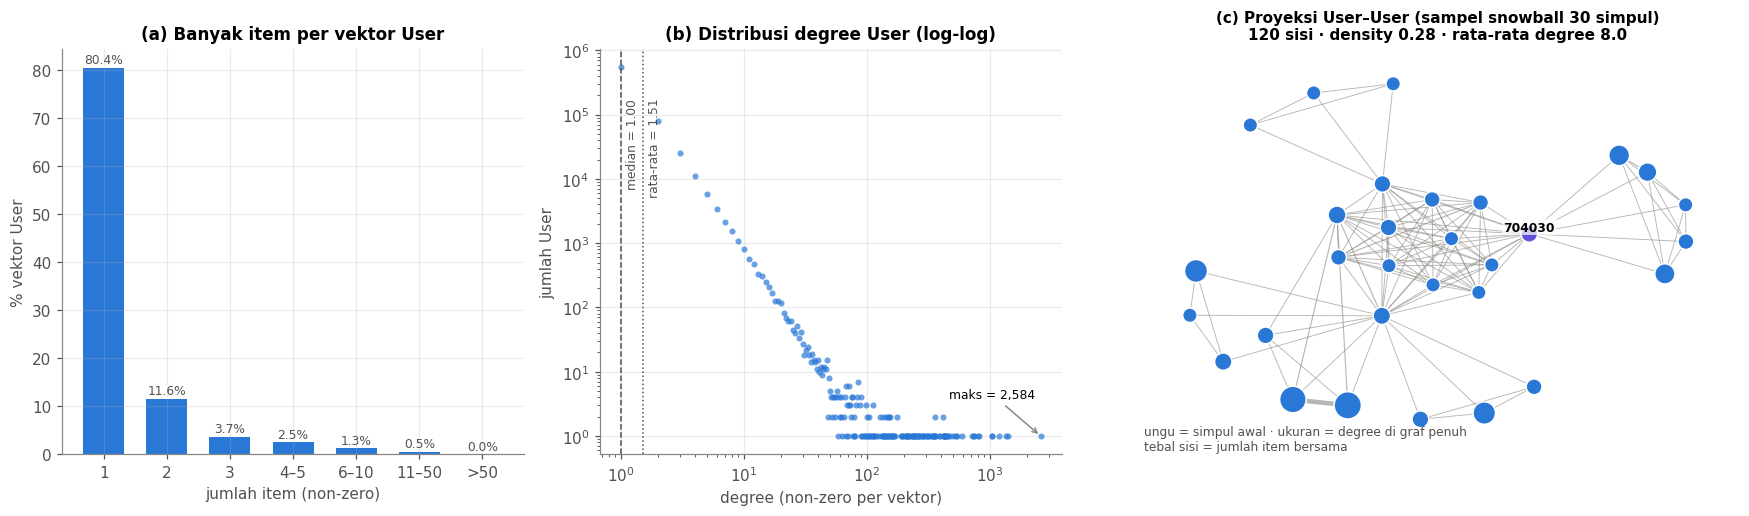

Visitor dengan 1 item: 80.4% | ≥ 2 item: 19.6% | > 10 item: 0.54%


In [21]:
prof_user = vsm_profile(X, "VSM User")
show_profile(prof_user)

deg_x = np.diff(X.indptr)
start_u = int(np.random.default_rng(SEED32).choice(np.flatnonzero((deg_x >= 3) & (deg_x <= 8))))
G_user, pct_user = vsm_figure(X, Xt, users, "User", C_USER, start_u, "item")
print(f"Visitor dengan 1 item: {pct_user['1']:.1f}% | ≥ 2 item: {100 - pct_user['1']:.1f}% | > 10 item: {pct_user[['11–50', '>50']].sum():.2f}%")

**Interpretasi No. 4 - VSM User**
- Terdapat **684.281 vektor user** berdimensi **171.044** (jumlah item P1) dengan hanya **1.031.265 nilai non-zero**, sehingga *density* ≈ **8,8 × 10⁻⁶** (99,999% sel bernilai nol). Matriks dense akan butuh **±468 GB**, sedangkan format sparse CSR hanya **±15 MB**, sehingga representasi sparse wajib dipakai.
- Grafik (a): **80,4%** visitor hanya menyentuh **1 item** (median = 1, rata-rata = 1,51). Hanya **19,6%** visitor yang punya ≥ 2 item.
- Grafik (b): titik-titik membentuk garis lurus menurun pada skala log-log, ciri distribusi **power-law / long-tail**: sangat banyak visitor dengan sedikit interaksi dan sangat sedikit visitor dengan interaksi banyak. Nilai maksimum **2.584 item** untuk satu visitor jauh di luar pola umum dan kemungkinan *bot/crawler*.
- Grafik (c): proyeksi User–User terbentuk dari visitor yang menyentuh item yang sama. Karena mayoritas visitor hanya punya 1 item, setiap visitor terhubung ke tetangganya hanya lewat satu item; sisi tebal (≥ 2 item bersama) jarang muncul. Kemiripan User–User jadi rapuh: dua user dianggap mirip hanya karena satu item yang kebetulan sama.

#### No. 5 - VSM simpul Item
Setiap item direpresentasikan sebagai vektor di ruang user: **i ∈ ℝ^|User|** (transpos matriks yang sama). Visualisasi sama seperti no. 4; sampel snowball dimulai dari **item terpopuler P1** (item acuan yang juga dipakai di no. 7).

jumlah vektor (baris),dimensi (kolom),non-zero,density,memori sparse CSR (MB),memori jika dense (GB),rata-rata nnz/vektor,median nnz/vektor,maks nnz/vektor,% vektor nnz = 1
"171,044","684,281","1,031,265",8.811e-06,13.06,468.17,6.03,2,"1,616",40.30


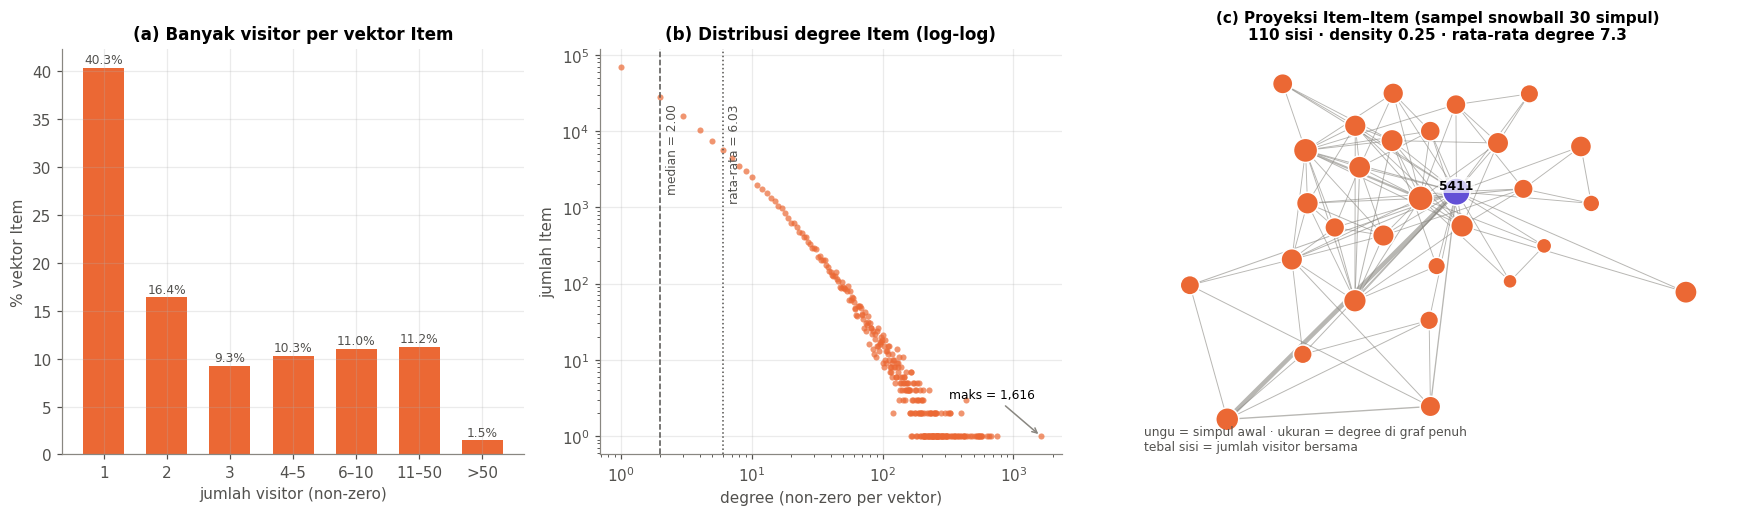

Item dengan 1 visitor: 40.3% | ≥ 2 visitor: 59.7% | > 10 visitor: 12.72%


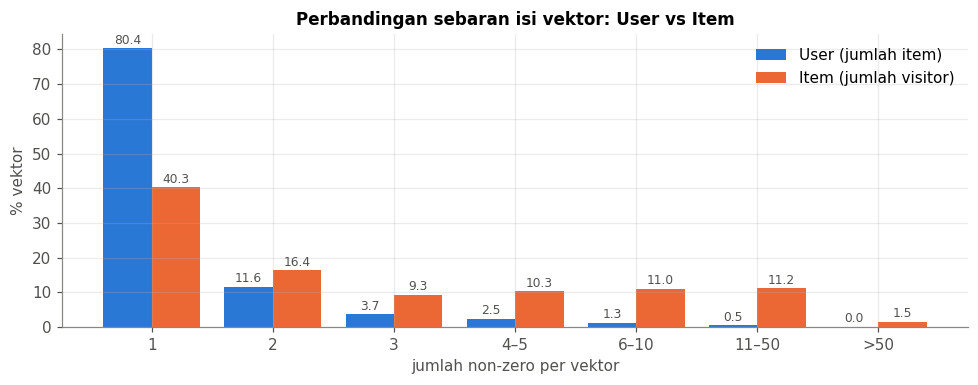

In [22]:
prof_item = vsm_profile(Xt, "VSM Item")
show_profile(prof_item)

start_i = int(np.argmax(np.diff(Xt.indptr)))
G_item, pct_item = vsm_figure(Xt, X, items, "Item", C_ITEM, start_i, "visitor")
print(f"Item dengan 1 visitor: {pct_item['1']:.1f}% | ≥ 2 visitor: {100 - pct_item['1']:.1f}% | > 10 visitor: {pct_item[['11–50', '>50']].sum():.2f}%")

# Perbandingan langsung User vs Item
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(BLABEL)); w = .4
bar_labels(ax, ax.bar(x - w / 2, pct_user.values, w, color=C_USER, label="User (jumlah item)"), "{:.1f}")
bar_labels(ax, ax.bar(x + w / 2, pct_item.values, w, color=C_ITEM, label="Item (jumlah visitor)"), "{:.1f}")
ax.set(xticks=x, xticklabels=BLABEL, xlabel="jumlah non-zero per vektor", ylabel="% vektor",
       title="Perbandingan sebaran isi vektor: User vs Item")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi No. 5 - VSM Item**
- Terdapat **171.044 vektor item** berdimensi **684.281** (jumlah visitor P1). Jumlah non-zero sama (**1.031.265**, matriks yang sama ditranspos), tetapi karena vektornya 4× lebih sedikit, isi per vektor jauh lebih padat: **rata-rata 6,03** visitor per item, **median 2** (vs 1,51 dan 1 pada user).
- Grafik (a) dan grafik perbandingan: hanya **40,3%** item yang disentuh 1 visitor; **59,7%** item punya ≥ 2 visitor (bandingkan dengan 19,6% pada user). Vektor item lebih sering beririsan sehingga similarity-nya lebih bermakna.
- Grafik (b) juga menunjukkan **power-law**: segelintir item sangat populer, dengan maksimum **1.616 visitor** pada item **5411** (item acuan no. 7).
- Grafik (c): proyeksi Item–Item di sekitar item 5411 lebih rapat dan banyak sisi tebal, karena visitor yang aktif cenderung melihat beberapa item sekaligus. Struktur ini lebih kaya informasi dibanding proyeksi User–User.

#### No. 6 - Proyeksi mana yang lebih baik (efektif/efisien)?
Dibandingkan secara kuantitatif:
- **Efisiensi:** jumlah simpul hasil proyeksi dan *jumlah pasangan* yang harus dihitung. Pasangan User–User yang berbagi item = Σ_item C(deg(item), 2); pasangan Item–Item = Σ_user C(deg(user), 2). Dihitung tanpa membentuk matriks proyeksi (murah).
- **Efektivitas:** porsi vektor dengan ≥ 2 non-zero (bisa punya irisan yang informatif) dan rata-rata non-zero per vektor.
- **Waktu nyata:** waktu menghitung similarity satu vektor acuan terhadap semua vektor lain.

In [23]:
def pairs(M):          # jumlah pasangan simpul sisi lain yang terhubung lewat baris M
    d = np.diff(M.indptr).astype(np.int64)
    return int((d * (d - 1) // 2).sum())

def time_one_query(M):
    Mn = normalize(M)
    ref = np.argmax(np.diff(M.indptr))
    t = time.perf_counter(); (Mn @ Mn[ref].T).toarray(); return time.perf_counter() - t

cmp = pd.DataFrame({
    "Proyeksi User–User": [X.shape[0],  pairs(Xt), (np.diff(X.indptr)  >= 2).mean() * 100, np.diff(X.indptr).mean(),  time_one_query(X)],
    "Proyeksi Item–Item": [Xt.shape[0], pairs(X),  (np.diff(Xt.indptr) >= 2).mean() * 100, np.diff(Xt.indptr).mean(), time_one_query(Xt)],
}, index=["jumlah simpul", "pasangan terhubung (sisi kandidat)", "% vektor nnz>=2", "rata-rata nnz/vektor", "waktu 1 query similarity (detik)"])
display(cmp.style.format("{:,.4f}"))

better = cmp.loc["pasangan terhubung (sisi kandidat)"].idxmin()
print("Proyeksi lebih efisien:", better)

,Proyeksi User–User,Proyeksi Item–Item
jumlah simpul,"684,281.0000","171,044.0000"
pasangan terhubung (sisi kandidat),"23,240,643.0000","13,831,358.0000"
% vektor nnz>=2,19.6440,59.6998
rata-rata nnz/vektor,1.5071,6.0292
waktu 1 query similarity (detik),0.0691,0.0332


Proyeksi lebih efisien: Proyeksi Item–Item


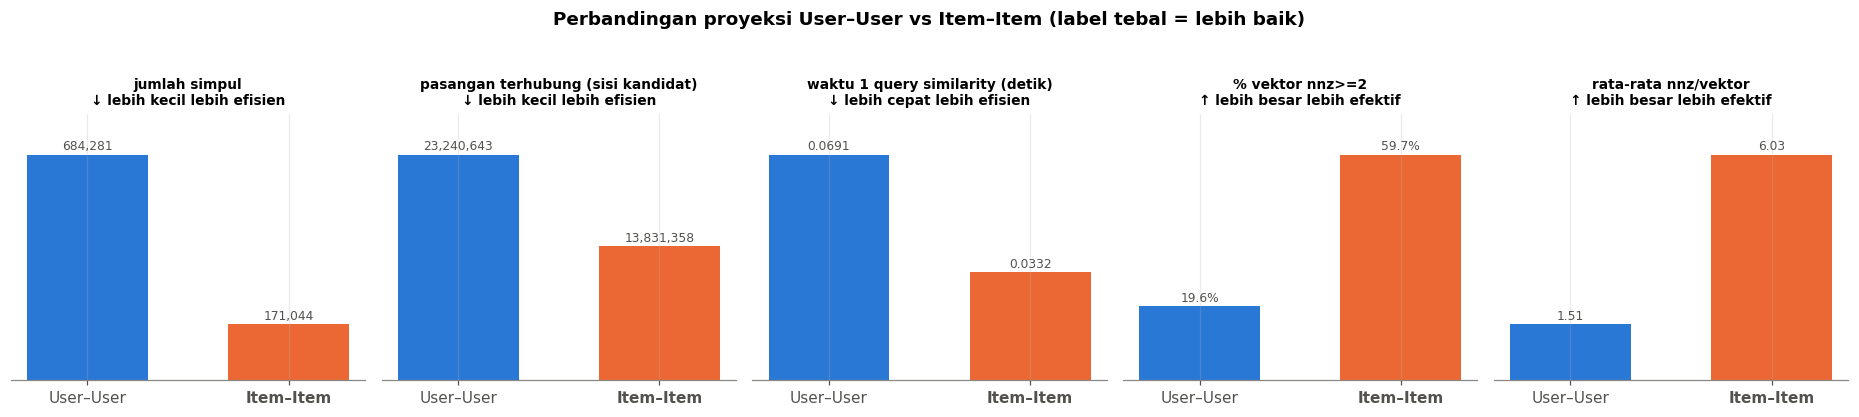

In [24]:
metrics = [("jumlah simpul", "↓ lebih kecil lebih efisien", "{:,.0f}"),
           ("pasangan terhubung (sisi kandidat)", "↓ lebih kecil lebih efisien", "{:,.0f}"),
           ("waktu 1 query similarity (detik)", "↓ lebih cepat lebih efisien", "{:.4f}"),
           ("% vektor nnz>=2", "↑ lebih besar lebih efektif", "{:.1f}%"),
           ("rata-rata nnz/vektor", "↑ lebih besar lebih efektif", "{:.2f}")]
fig, ax = plt.subplots(1, 5, figsize=(17, 3.6))
for a, (m, goal, fmt) in zip(ax, metrics):
    v = cmp.loc[m]
    b = a.bar(["User–User", "Item–Item"], v.values, color=[C_USER, C_ITEM], width=.6)
    bar_labels(a, b, fmt)
    best = v.idxmin() if goal.startswith("↓") else v.idxmax()
    a.set_title(f"{m}\n{goal}", fontsize=9)
    a.get_xticklabels()[list(v.index).index(best)].set_fontweight("bold")
    a.set_ylim(0, v.max() * 1.18); a.yaxis.set_visible(False); a.spines["left"].set_visible(False)
fig.suptitle("Perbandingan proyeksi User–User vs Item–Item (label tebal = lebih baik)", weight="bold", y=1.04)
plt.tight_layout(); plt.show()

**Kesimpulan No. 6 - proyeksi Item–Item lebih baik.** Kelima indikator berpihak ke Item–Item:

| Indikator | User–User | Item–Item | Keterangan |
|---|---|---|---|
| Jumlah simpul | 684.281 | 171.044 | 4× lebih sedikit |
| Pasangan terhubung | 23,24 juta | 13,83 juta | ±40% lebih sedikit sisi yang harus dihitung |
| Waktu 1 query similarity | ±0,069 s | ±0,033 s | ±2× lebih cepat (angka waktu bisa sedikit berbeda tiap dijalankan) |
| % vektor nnz ≥ 2 | 19,6% | 59,7% | 3× lebih banyak vektor yang bisa beririsan |
| Rata-rata nnz/vektor | 1,51 | 6,03 | vektor 4× lebih padat |

- **Efisien:** simpul dan sisi lebih sedikit, sehingga memori dan waktu komputasi lebih kecil. Proyeksi User–User justru membengkak karena item populer (mis. 5411 dengan 1.616 visitor) menghasilkan ribuan pasangan user sekaligus.
- **Efektif:** 80% vektor user hanya berisi 1 item, sehingga cosine User–User hampir selalu 0 atau ditentukan oleh satu item saja. Vektor item lebih padat sehingga nilai similarity lebih stabil.
- Katalog item juga lebih stabil antar-periode (78,6% item P2 sudah ada di P1, sedangkan visitor hanya 6,3%; lihat no. 3), sehingga hasil similarity Item–Item tetap berguna di masa uji.

Karena itu similarity no. 7–8 dihitung pada **proyeksi Item–Item**.

#### No. 7 - Similarity pada graf terproyeksi (Python)
Ukuran: **cosine similarity berbobot** antar vektor item:

$$\cos(a,b)=\frac{\sum_v w_{va}\,w_{vb}}{\lVert a\rVert\,\lVert b\rVert}$$

Item acuan = **item dengan degree tertinggi di P1** (deterministik). Python cukup menghitung satu baris (vektor acuan × seluruh item) dengan perkalian sparse — tidak perlu matriks Item×Item penuh.

In [25]:
Xn = normalize(Xt)                                 # L2-normalisasi tiap vektor item
ref = int(np.argmax(np.diff(Xt.indptr)))
REF_ITEM = int(items[ref])

sims = (Xn @ Xn[ref].T).toarray().ravel()
sims[ref] = -1                                     # abaikan diri sendiri
top5 = np.argsort(-sims)[:5]
py_top5 = pd.DataFrame({"item": items[top5].astype(int), "cosine_python": sims[top5].round(6)})
print("Item acuan:", REF_ITEM, "| degree:", np.diff(Xt.indptr)[ref])
py_top5

Item acuan: 5411 | degree: 1616


,item,cosine_python
0,33030,0.165460
1,256242,0.127863
2,33956,0.108185
3,37807,0.102079
4,459936,0.090442


##### 7(a) - Cypher: 5 record dengan similarity tertinggi
Norma tiap vektor item (‖i‖) ditulis dulu sebagai properti `norm_p1` (sekali, batch `UNWIND`). Query lalu menghitung cosine langsung di graf:

1. `MATCH (ref)<-[e1]-(v)` - ambil semua visitor P1 yang menyentuh item acuan, jumlahkan bobotnya → `wr`.
2. `MATCH (v)-[e2]->(o)` - dari visitor yang sama, ambil item lain beserta bobotnya → `wo` (ini adalah **proyeksi Item–Item** lewat visitor bersama).
3. `sum(wr*wo)` = dot product; dibagi `ref.norm_p1 * o.norm_p1` = cosine. Urutkan menurun, ambil 5.


In [26]:
norms = np.sqrt(Xt.multiply(Xt).sum(axis=1)).A1
rows = [{"id": int(a), "norm": float(b)} for a, b in zip(items, norms)]
for k in range(0, len(rows), 20_000):
    q("UNWIND $rows AS r MATCH (i:Item {itemId: r.id}) SET i.norm_p1 = r.norm", write=True, rows=rows[k:k + 20_000])

CYPHER_TOP5 = f'''
MATCH (ref:Item {{itemId: $ref}})<-[e1]-(v:Visitor)
WHERE e1.fold = 'P1'
WITH ref, v, sum({case_w("e1")}) AS wr
MATCH (v)-[e2]->(o:Item)
WHERE e2.fold = 'P1' AND o <> ref
WITH ref, o, v, wr, sum({case_w("e2")}) AS wo
WITH ref, o, sum(wr * wo) AS dot
RETURN o.itemId AS item, round(dot / (ref.norm_p1 * o.norm_p1), 6) AS cosine_cypher
ORDER BY cosine_cypher DESC, item
LIMIT 5
'''
print(CYPHER_TOP5)
cy_top5 = q(CYPHER_TOP5, ref=REF_ITEM)
chk = cy_top5.merge(py_top5, on="item", how="left")          # urutan mengikuti hasil Cypher
chk["selisih"] = (chk.cosine_cypher - chk.cosine_python).abs()
print("Python = Cypher (toleransi 1e-6):", bool((chk.selisih <= 1e-6).all()))
chk


MATCH (ref:Item {itemId: $ref})<-[e1]-(v:Visitor)
WHERE e1.fold = 'P1'
WITH ref, v, sum(CASE type(e1) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 END) AS wr
MATCH (v)-[e2]->(o:Item)
WHERE e2.fold = 'P1' AND o <> ref
WITH ref, o, v, wr, sum(CASE type(e2) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 3 WHEN 'BOUGHT' THEN 5 END) AS wo
WITH ref, o, sum(wr * wo) AS dot
RETURN o.itemId AS item, round(dot / (ref.norm_p1 * o.norm_p1), 6) AS cosine_cypher
ORDER BY cosine_cypher DESC, item
LIMIT 5

Python = Cypher (toleransi 1e-6): True


,item,cosine_cypher,cosine_python,selisih
0,33030,0.165460,0.165460,0.0
1,256242,0.127863,0.127863,0.0
2,33956,0.108185,0.108185,0.0
3,37807,0.102079,0.102079,0.0
4,459936,0.090442,0.090442,0.0


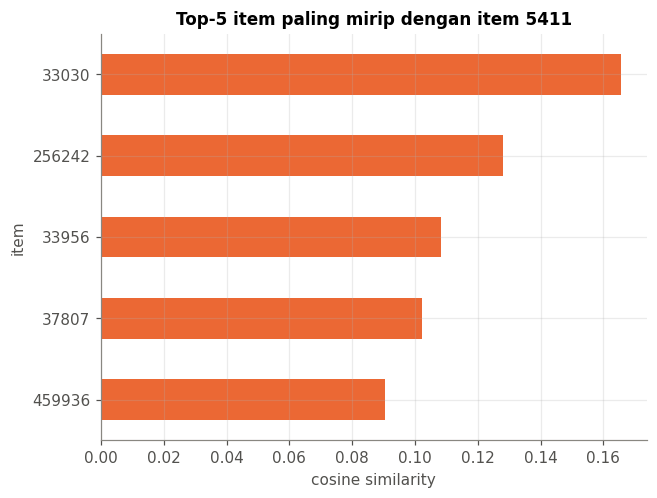

,item,cosine,visitor_bersama
0,33030,0.1655,66
1,256242,0.1279,1
2,33956,0.1082,19
3,37807,0.1021,15
4,459936,0.0904,31


In [35]:
# Visualisasi top-5 similarity + jumlah visitor bersama
shared = [len(set(Xt[ref].indices) & set(Xt[i].indices)) for i in top5]   # visitor yang melihat kedua item

viz7 = pd.DataFrame({"item": items[top5].astype(str), "cosine": sims[top5].round(4), "visitor_bersama": shared})
viz7.plot.barh(x="item", y="cosine", color=C_ITEM, legend=False,
               title=f"Top-5 item paling mirip dengan item {REF_ITEM}").invert_yaxis()
plt.xlabel("cosine similarity"); plt.show()
viz7

**Interpretasi No. 7**
- Item acuan **5411** adalah item dengan degree tertinggi di P1 (**1.616 visitor**). Lima item paling mirip: **33030 (0,1655)**, **256242 (0,1279)**, **33956 (0,1082)**, **37807 (0,1021)**, dan **459936 (0,0904)**.
- Nilai Cypher dan Python **identik sampai 6 desimal** (kolom `selisih` = 0), jadi perhitungan cosine langsung di Neo4j sudah benar.
- Nilai cosine kecil (< 0,17) karena norma item 5411 sangat besar (1.616 visitor), sedangkan visitor bersamanya hanya 1–66 orang (kolom `visitor_bersama`).
- **33030** paling mirip dan didukung **66 visitor bersama**, jadi hasilnya kuat.
- **256242** ada di peringkat 2 padahal hanya punya **1 visitor bersama**. Item ini hampir tidak punya visitor lain, sehingga normanya kecil dan cosine-nya terdongkrak. Ini kelemahan cosine pada item yang sangat jarang dilihat; dalam praktik biasanya diberi syarat minimal jumlah visitor bersama.

##### 7(b) - Tulis kembali nilai similarity ke graf
Lima nilai similarity disimpan sebagai relasi baru `(:Item)-[:SIMILAR_TO {score, method, fold}]->(:Item)`. `MERGE` dipakai agar idempoten (dijalankan ulang tidak menggandakan relasi).

In [28]:
before_cnt = q("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS similar_to_sebelum")

q('''
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.item})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.method = 'cosine_weighted', s.fold = 'P1'
''', write=True, ref=REF_ITEM,
  rows=[{"item": int(i), "score": float(s)} for i, s in zip(py_top5.item, py_top5.cosine_python)])

after = q('''
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS score, s.method AS method
ORDER BY score DESC
''', ref=REF_ITEM)
display(before_cnt, after)

,similar_to_sebelum
0,0


,item_acuan,item_mirip,score,method
0,5411,33030,0.165460,cosine_weighted
1,5411,256242,0.127863,cosine_weighted
2,5411,33956,0.108185,cosine_weighted
3,5411,37807,0.102079,cosine_weighted
4,5411,459936,0.090442,cosine_weighted


#### No. 8 - Kondisi sebelum dan sesudah perhitungan similarity

**Sebelum:** kemiripan antar item hanya *implisit* — dua item terkait lewat jalur 2-hop `Item ← Visitor → Item`. Query:
```cypher
MATCH p = (a:Item {itemId: $ref})<-[e1]-(v:Visitor)-[e2]->(b:Item)
WHERE b.itemId IN $top5 AND e1.fold = 'P1' AND e2.fold = 'P1'
RETURN p
```
**Sesudah:** kemiripan menjadi relasi *eksplisit* 1-hop berbobot:
```cypher
MATCH p = (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN p
```

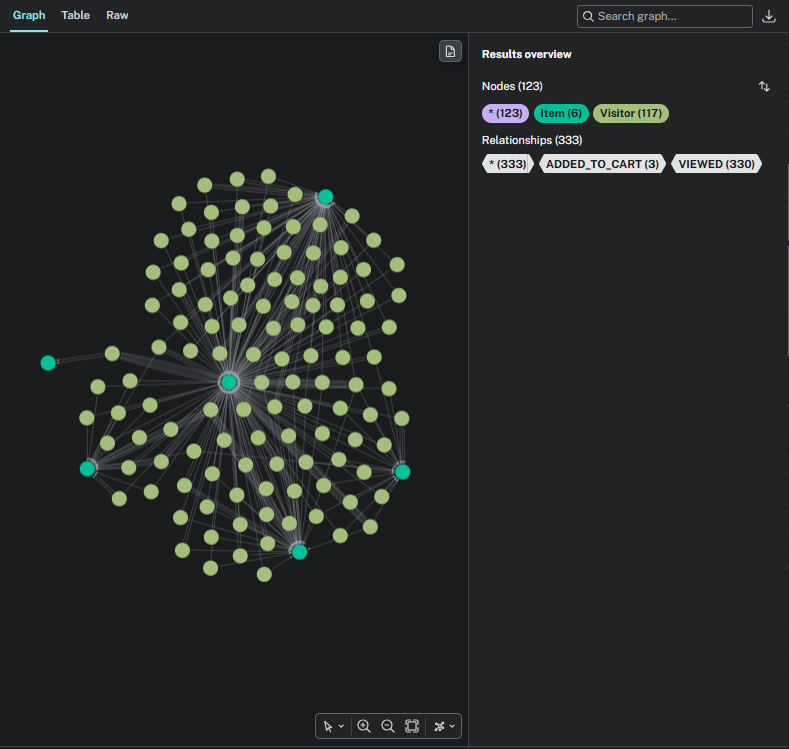

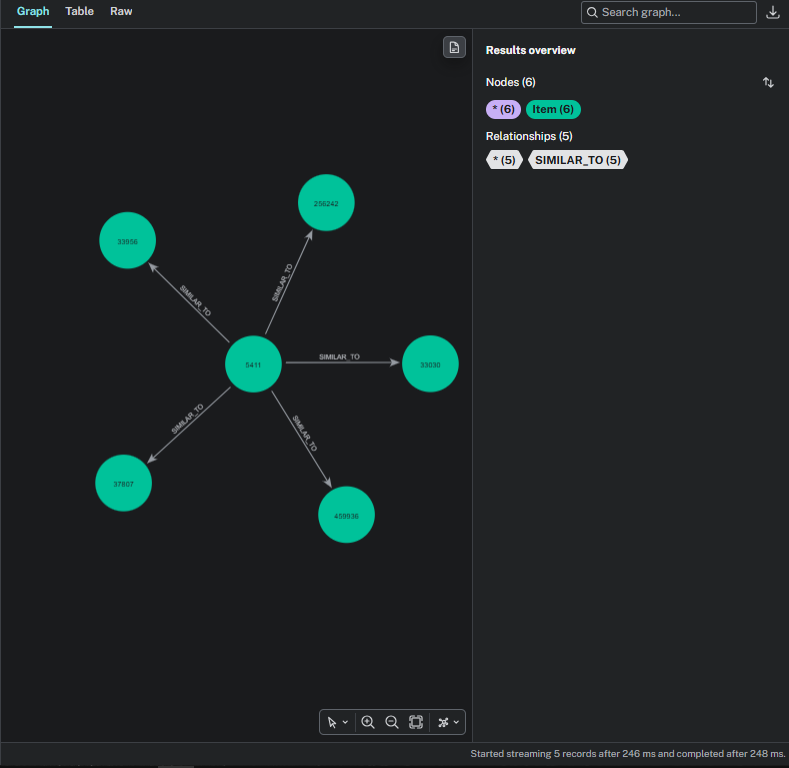

,SEBELUM (hitung dari jalur 2-hop),SESUDAH (baca SIMILAR_TO)
pola jalur,Item ← Visitor → Item (2 hop),Item → Item (1 hop)
yang ditelusuri,"1,616 visitor + semua item mereka",5 relasi
waktu query (median 3x),81.5 ms,22.9 ms


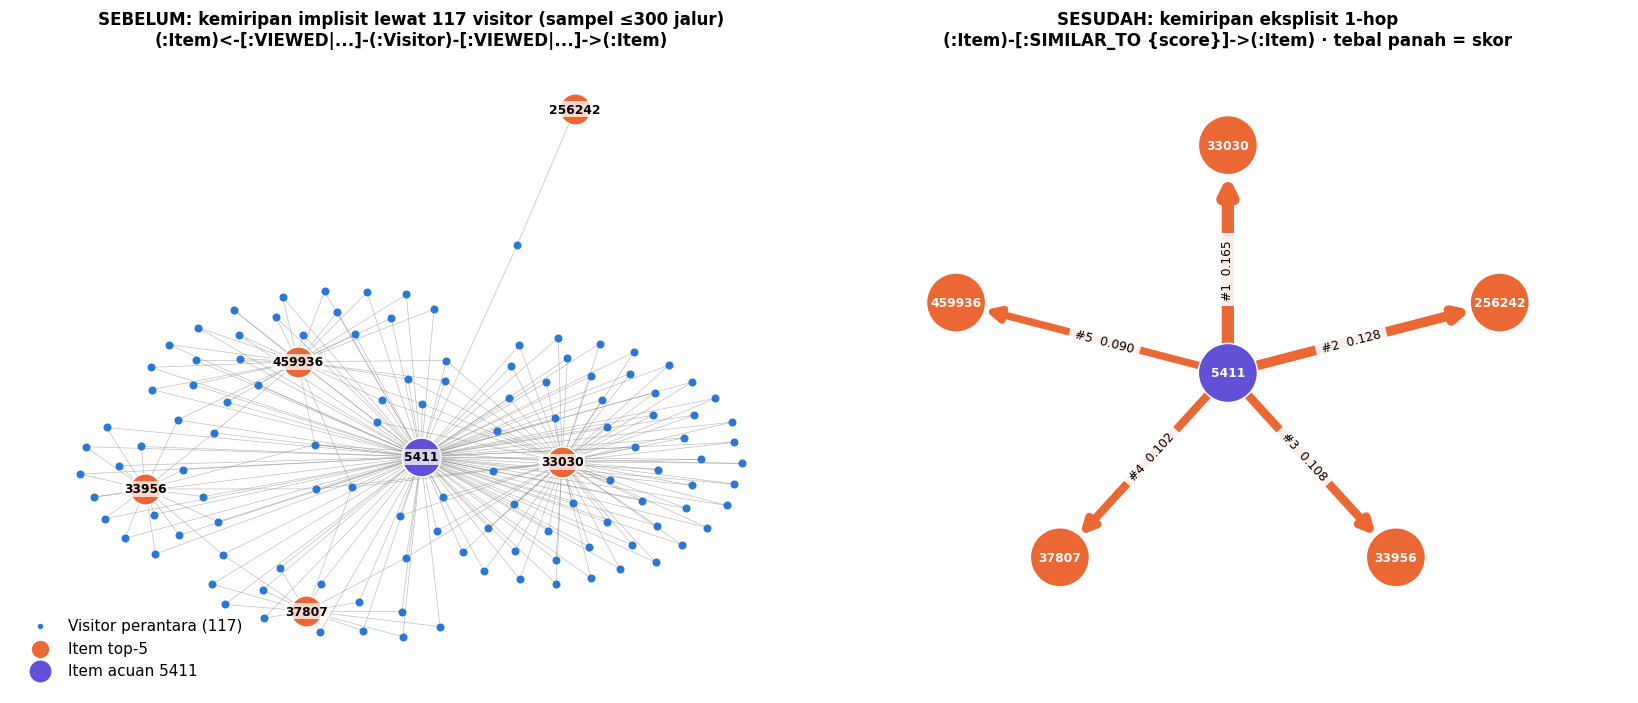

In [ ]:
TOP5 = [int(i) for i in py_top5.item]
before_df = q('''
MATCH (a:Item {itemId: $ref})<-[e1]-(v:Visitor)-[e2]->(b:Item)
WHERE b.itemId IN $top5 AND e1.fold = 'P1' AND e2.fold = 'P1'
RETURN DISTINCT a.itemId AS a, v.visitorId AS v, b.itemId AS b
LIMIT 300
''', ref=REF_ITEM, top5=TOP5)

# --- ukuran kuantitatif: biaya query sebelum vs sesudah
def timeit(cy, n=3, **p):
    ts = []
    for _ in range(n):
        t = time.perf_counter(); q(cy, **p); ts.append(time.perf_counter() - t)
    return np.median(ts)
CY_AFTER = "MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item) RETURN b.itemId AS item, s.score AS score ORDER BY score DESC"
t_before, t_after = timeit(CYPHER_TOP5, ref=REF_ITEM), timeit(CY_AFTER, ref=REF_ITEM)
cost = pd.DataFrame({
    "SEBELUM (hitung dari jalur 2-hop)": ["Item ← Visitor → Item (2 hop)", f"{np.diff(Xt.indptr)[ref]:,} visitor + semua item mereka", f"{t_before * 1000:,.1f} ms"],
    "SESUDAH (baca SIMILAR_TO)":        ["Item → Item (1 hop)", "5 relasi", f"{t_after * 1000:,.1f} ms"],
}, index=["pola jalur", "yang ditelusuri", "waktu query (median 3x)"])
display(cost)

fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
# --- SEBELUM: graf bipartit Item-Visitor-Item 
Gb = nx.Graph()
Gb.add_edges_from((f"I{a}", f"V{v}") for a, v in zip(before_df.a, before_df.v))
Gb.add_edges_from((f"V{v}", f"I{b}") for v, b in zip(before_df.v, before_df.b))
pos = nx.spring_layout(Gb, seed=SEED32, k=0.3, iterations=200)
vis = [n for n in Gb if n[0] == "V"]; itm = [n for n in Gb if n[0] == "I" and n != f"I{REF_ITEM}"]
nx.draw_networkx_edges(Gb, pos, ax=ax[0], width=.4, edge_color=C_MUTED, alpha=.6)
nx.draw_networkx_nodes(Gb, pos, nodelist=vis, ax=ax[0], node_size=18, node_color=C_USER, label=f"Visitor perantara ({len(vis)})")
nx.draw_networkx_nodes(Gb, pos, nodelist=itm, ax=ax[0], node_size=420, node_color=C_ITEM, edgecolors="white", label="Item top-5")
nx.draw_networkx_nodes(Gb, pos, nodelist=[f"I{REF_ITEM}"], ax=ax[0], node_size=650, node_color=C_REF, edgecolors="white", label=f"Item acuan {REF_ITEM}")
nx.draw_networkx_labels(Gb, pos, {n: n[1:] for n in itm + [f"I{REF_ITEM}"]}, ax=ax[0], font_size=8, font_weight="bold",
                        bbox=dict(fc="white", ec="none", alpha=.75, pad=1))
ax[0].legend(loc="lower left", scatterpoints=1, markerscale=.6)
ax[0].set_title(f"SEBELUM: kemiripan implisit lewat {len(vis)} visitor (sampel ≤300 jalur)\n(:Item)<-[:VIEWED|...]-(:Visitor)-[:VIEWED|...]->(:Item)")
ax[0].axis("off")

# --- SESUDAH: relasi SIMILAR_TO eksplisit
Ga = nx.DiGraph()
Ga.add_weighted_edges_from(zip(after.item_acuan, after.item_mirip, after.score))
ang = np.linspace(90, 90 - 360, 6)[:-1] * np.pi / 180
pos = {REF_ITEM: np.array([0, 0])}
pos.update({int(n): np.array([np.cos(t), np.sin(t)]) for n, t in zip(after.item_mirip, ang)})
wmax = after.score.max()
nx.draw_networkx_edges(Ga, pos, ax=ax[1], width=[1 + 7 * d["weight"] / wmax for *_, d in Ga.edges(data=True)],
                       edge_color=C_ITEM, arrowsize=18, node_size=1500)
nx.draw_networkx_nodes(Ga, pos, ax=ax[1], node_size=1500, edgecolors="white",
                       node_color=[C_REF if n == REF_ITEM else C_ITEM for n in Ga])
nx.draw_networkx_labels(Ga, pos, ax=ax[1], font_size=8, font_color="white", font_weight="bold")
nx.draw_networkx_edge_labels(Ga, pos, ax=ax[1], font_size=8, label_pos=.45,
                             edge_labels={(u, v): f"#{k + 1}  {d['weight']:.3f}" for k, (u, v, d) in enumerate(sorted(Ga.edges(data=True), key=lambda e: -e[2]['weight']))},
                             bbox=dict(fc="white", ec="none", alpha=.9))
ax[1].set_title("SESUDAH: kemiripan eksplisit 1-hop\n(:Item)-[:SIMILAR_TO {score}]->(:Item) · tebal panah = skor")
ax[1].set_xlim(-1.4, 1.4); ax[1].set_ylim(-1.4, 1.4); ax[1].axis("off")
plt.tight_layout(); plt.show()

**Interpretasi No. 8**
- **Sebelum:** graf hanya berisi relasi Visitor → Item. Kemiripan item 5411 dengan item lain bersifat **implisit**: hanya bisa diketahui dengan menelusuri jalur 2-hop `Item ← Visitor → Item`. Grafik kiri (sampel ≤ 300 jalur) sudah melibatkan **117 visitor perantara** hanya untuk 5 item. Untuk menghitung skornya, query harus menelusuri seluruh 1.616 visitor item 5411 beserta semua item yang mereka lihat, lalu menjumlahkan dan menormalisasi bobotnya.
- **Sesudah:** hasilnya tersimpan sebagai **5 relasi `SIMILAR_TO` berbobot** (grafik kanan). Graf kini punya sisi Item–Item langsung, sehingga item yang mirip dan peringkatnya cukup dibaca dengan **query 1-hop** tanpa perhitungan ulang. TWaktu query turun dari **81,5 ms** (hitung ulang lewat 2-hop) menjadi **22,9 ms** (baca `SIMILAR_TO`), sekitar 3,6× lebih cepat.
- Struktur graf berubah dari **bipartit murni** menjadi graf dengan lapisan pengetahuan tambahan (sisi Item–Item). Lapisan ini bisa langsung dipakai untuk fitur *"produk serupa"* atau sebagai dasar rekomendasi item-based.

### 2.2 Analytics

#### No. 1 - User acak (reproducible) & rekomendasi KNN
**Proses acak:** kandidat = visitor yang (i) punya ≥ 3 item berbeda di P1 (vektornya cukup informatif untuk mencari tetangga) dan (ii) juga aktif di P2 (agar Hit/NDCG bisa dievaluasi). Kandidat diurutkan, lalu dipilih dengan `np.random.default_rng(SEED)` (SEED = NIM), sehingga hasilnya selalu sama.

**Metode (user-based KNN, k = 5, cosine):**
1. **Kolam tetangga** = visitor P1 dengan ≥ 2 item. Visitor yang hanya punya 1 item tidak bisa menyumbang item baru: kalau item satu-satunya juga dimiliki target, skornya pasti 0.
2. Cari 200 visitor terdekat (cosine), lalu ambil **5 tetangga teratas yang memiliki minimal 1 item yang belum pernah disentuh target**. Hasil awal tanpa filter ini menunjukkan 5 tetangga dengan cosine sama (0,2747) yang masing-masing hanya punya 1 item, sehingga semua skor rekomendasi bernilai 0.
3. Skor item = Σ cosine(tetangga) × bobot interaksi tetangga dengan item tersebut. Item yang sudah dilihat target dibuang.
4. Ranking top-5; **3 teratas = item yang diiklankan**. Fallback item terpopuler P1 hanya dipakai bila kandidat < 5.

In [30]:
K, N_REC, N_ADS, SEARCH = 5, 5, 3, 200

deg_u = pd.Series(np.diff(X.indptr), index=users)
te_items = te.groupby("u")["i"].agg(set)
cand = np.sort(deg_u[(deg_u >= 3) & deg_u.index.isin(te_items.index)].index.to_numpy())
rng = np.random.default_rng(SEED)
TARGET = int(rng.choice(cand))
print(f"Kandidat user: {len(cand):,} | user terpilih (SEED={SEED}): {TARGET}")

pool = np.flatnonzero(np.diff(X.indptr) >= 2)                     # kolam tetangga: >= 2 item
knn = NearestNeighbors(metric="cosine", algorithm="brute").fit(X[pool])
pop_rank = np.argsort(-np.diff(Xt.indptr))
print(f"Kolam tetangga: {len(pool):,} visitor (≥ 2 item)")

def recommend_knn(uid, k=K, n=N_REC):
    row = user_pos[uid]; seen = X[row].indices
    dist, idx = knn.kneighbors(X[row], n_neighbors=min(SEARCH, len(pool)))
    cand_nb, sim = pool[idx[0]], 1 - dist[0]
    Xc = X[cand_nb]
    new_cnt = np.diff(Xc.indptr) - Xc[:, seen].getnnz(axis=1)       # item baru yang dimiliki tetangga
    keep = (cand_nb != row) & (sim > 0) & (new_cnt > 0)
    nb, sim, new_cnt = cand_nb[keep][:k], sim[keep][:k], new_cnt[keep][:k]
    scores = np.asarray(X[nb].T @ sim).ravel()
    scores[seen] = 0
    ranked = np.argsort(-scores)[:n]
    ranked = ranked[scores[ranked] > 0]
    src = ["KNN"] * len(ranked)
    if len(ranked) < n:                                             # fallback popularitas
        used = set(seen) | set(ranked)
        extra = [i for i in pop_rank[: n + len(used)] if i not in used][: n - len(ranked)]
        ranked = np.r_[ranked, extra].astype(int); src += ["populer"] * len(extra)
    neigh = pd.DataFrame({"visitor_tetangga": users[nb], "cosine": sim.round(4),
                          "jml_item": np.diff(X.indptr)[nb], "item_baru": new_cnt})
    recs = pd.DataFrame({"rank": np.arange(1, len(ranked) + 1), "itemId": items[ranked].astype(int),
                         "skor": scores[ranked].round(4), "sumber": src})
    return neigh, recs

print(f"Riwayat P1 user ({deg_u[TARGET]} item):", sorted(items[X[user_pos[TARGET]].indices].astype(int).tolist()))
neigh, recs = recommend_knn(TARGET)
display(neigh, recs)

Kandidat user: 2,626 | user terpilih (SEED=23031554192): 874209
Kolam tetangga: 134,420 visitor (≥ 2 item)
Riwayat P1 user (50 item): [5307, 7471, 18058, 21840, 32672, 57413, 79225, 85914, 99418, 99476, 99610, 111121, 119446, 120183, 147095, 155196, 156358, 157055, 167109, 188333, 195688, 206218, 208030, 222461, 230871, 239330, 242981, 244027, 268355, 270749, 272324, 277834, 277943, 279885, 281710, 301720, 304257, 311979, 325759, 354693, 365090, 367734, 370829, 372188, 386701, 403475, 440313, 445059, 445563, 453510]


,visitor_tetangga,cosine,jml_item,item_baru
0,1324244,0.2606,2,1
1,9004,0.2286,2,1
2,800275,0.2172,4,1
3,234487,0.2077,4,1
4,51442,0.2077,4,3


,rank,itemId,skor,sumber
0,1,269258,0.4572,KNN
1,2,318117,0.2606,KNN
2,3,310608,0.2172,KNN
3,4,396930,0.2077,KNN
4,5,14214,0.2077,KNN


#### No. 1(b) - 3 item yang diiklankan (k = 5)

In [31]:
ads = recs.head(N_ADS).assign(diiklankan="✔")
print(f"3 item yang diiklankan untuk user {TARGET}:", ads.itemId.tolist())
ads

3 item yang diiklankan untuk user 874209: [269258, 318117, 310608]


,rank,itemId,skor,sumber,diiklankan
0,1,269258,0.4572,KNN,✔
1,2,318117,0.2606,KNN,✔
2,3,310608,0.2172,KNN,✔


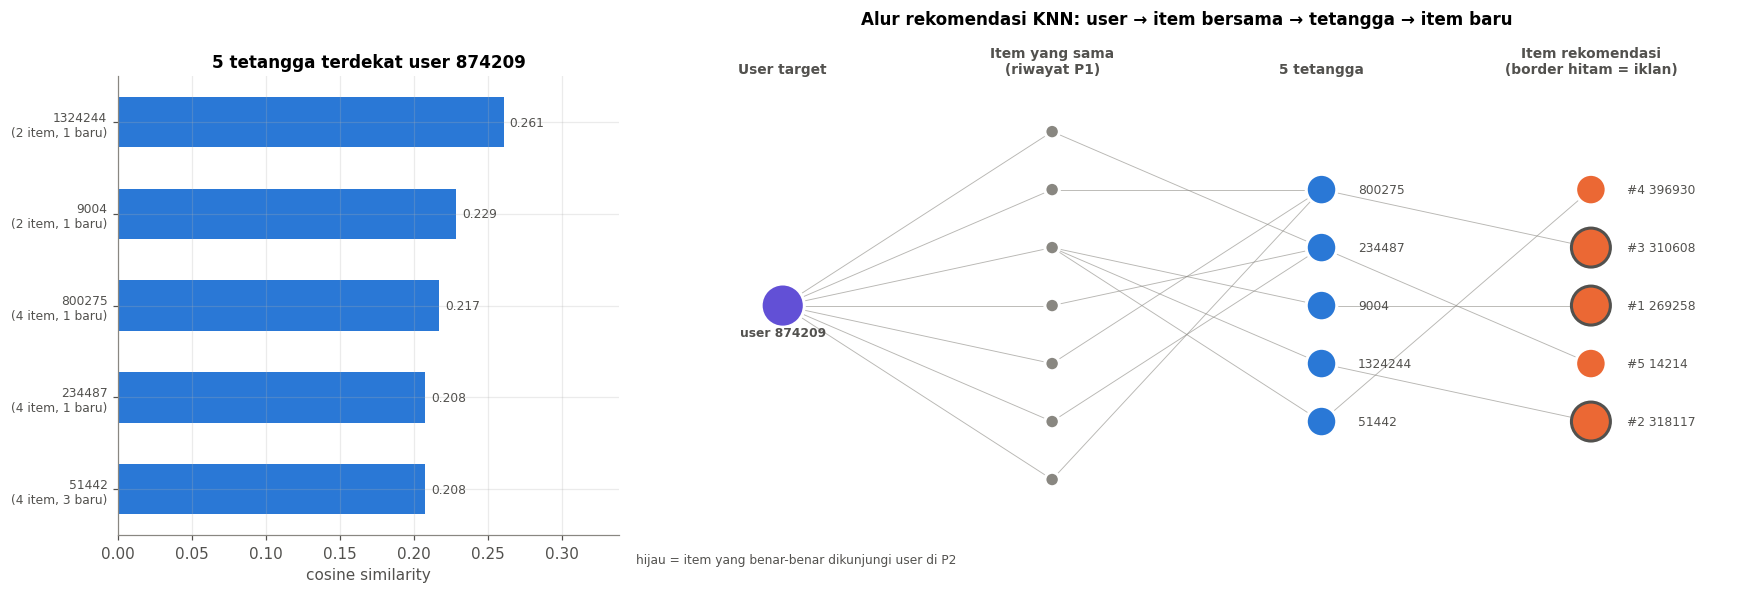

In [32]:
trow = user_pos[TARGET]; seen = set(X[trow].indices)
nb_rows = user_pos[neigh.visitor_tetangga].to_numpy()
rec_cols = item_pos[recs.itemId].to_numpy()
G = nx.Graph()
G.add_node("U", layer=0)
for r, s in zip(nb_rows, neigh.cosine):
    G.add_node(f"N{r}", layer=2)
    for c in X[r].indices:
        if c in seen:   G.add_node(f"S{c}", layer=1); G.add_edge("U", f"S{c}"); G.add_edge(f"S{c}", f"N{r}")
        elif c in rec_cols: G.add_node(f"R{c}", layer=3); G.add_edge(f"N{r}", f"R{c}")
for c in rec_cols: G.add_node(f"R{c}", layer=3)
pos = nx.multipartite_layout(G, subset_key="layer")

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 2.2]})
y = np.arange(len(neigh))[::-1]
b = ax[0].barh(y, neigh.cosine, color=C_USER, height=.55)
bar_labels(ax[0], b, "{:.3f}", horizontal=True)
ax[0].set(yticks=y, yticklabels=[f"{v}\n({j} item, {nw} baru)" for v, j, nw in zip(neigh.visitor_tetangga, neigh.jml_item, neigh.item_baru)],
          xlim=(0, max(neigh.cosine.max() * 1.3, .05)), xlabel="cosine similarity", title=f"5 tetangga terdekat user {TARGET}")
ax[0].tick_params(axis="y", labelsize=8)

relevant_cols = {item_pos[i] for i in te_items[TARGET] if i in item_pos.index}
ads_cols = set(rec_cols[:N_ADS])
col = {"U": C_REF, "S": C_MUTED, "N": C_USER}
nc, ns, ec = [], [], []
for n in G:
    if n[0] == "R":
        c = int(n[1:]); nc.append(C_BUY if c in relevant_cols else C_ITEM); ns.append(650 if c in ads_cols else 400)
        ec.append(C_INK if c in ads_cols else "white")
    else:
        nc.append(col[n[0]]); ns.append({"U": 800, "S": 90, "N": 400}[n[0]]); ec.append("white")
nx.draw_networkx_edges(G, pos, ax=ax[1], edge_color=C_MUTED, width=.6, alpha=.6)
nx.draw_networkx_nodes(G, pos, ax=ax[1], node_color=nc, node_size=ns, edgecolors=ec, linewidths=2)
lbl = {"U": f"user\n{TARGET}"} | {f"R{c}": f"#{k + 1}\n{items[c]}" for k, c in enumerate(rec_cols)} | {f"N{r}": str(users[r]) for r in nb_rows}
xs = sorted({p[0] for p in pos.values()}); dx = (xs[-1] - xs[0]) * .045
for n, t in lbl.items():
    x0, y0 = pos[n]
    if n == "U": ax[1].text(x0, y0 - .12, t.replace("\n", " "), ha="center", va="top", fontsize=8, weight="bold", color=C_INK)
    else: ax[1].text(x0 + dx, y0, t.replace("\n", " "), ha="left", va="center", fontsize=8, color=C_INK)
from matplotlib.transforms import blended_transform_factory
tr_ = blended_transform_factory(ax[1].transData, ax[1].transAxes)
for xl, t in zip(xs, ["User target", "Item yang sama\n(riwayat P1)", "5 tetangga", "Item rekomendasi\n(border hitam = iklan)"]):
    ax[1].text(xl, 1.0, t, ha="center", va="bottom", fontsize=9, weight="bold", color=C_INK, transform=tr_)
ax[1].set_title("Alur rekomendasi KNN: user → item bersama → tetangga → item baru", pad=34)
ax[1].text(.0, -.06, "hijau = item yang benar-benar dikunjungi user di P2", transform=ax[1].transAxes, fontsize=8, color=C_INK)
ax[1].margins(x=.12, y=.1); ax[1].axis("off")
plt.tight_layout(); plt.show()

**Interpretasi No. 1**
- User terpilih **874209** (50 item di P1). Lima tetangganya punya cosine **0,208–0,261**, semuanya dengan 2–4 item, sehingga tiap tetangga bisa menyumbang item baru.
- 3 item yang diiklankan: **269258, 318117, 310608**. Semua rekomendasi berasal dari KNN (kolom `sumber`), bukan fallback popularitas.
- Item 269258 mendapat skor tertinggi (0,4572) karena tetangga 9004 (cosine 0,2286) berinteraksi dengannya dengan bobot 2: 0,2286 × 2 = 0,4572.

#### No. 2 - Hit@5 dan NDCG@5
Ground truth = himpunan item yang disentuh user target pada **P2** (relevansi biner).

$$\text{Hit@5}=\mathbb{1}\left[\,|\text{Top5}\cap\text{Rel}|>0\,\right],\qquad
\text{DCG@5}=\sum_{r=1}^{5}\frac{\text{rel}_r}{\log_2(r+1)},\qquad
\text{NDCG@5}=\frac{\text{DCG@5}}{\text{IDCG@5}}$$

IDCG@5 = DCG ideal bila semua item relevan berada di peringkat teratas, yaitu Σ_{r=1}^{min(|Rel|,5)} 1/log₂(r+1).

In [34]:
def hit_ndcg(rec, relevant, k=5):
    rec = list(rec)[:k]
    rel = [int(i in relevant) for i in rec]
    dcg  = sum(r / np.log2(p + 2) for p, r in enumerate(rel))
    idcg = sum(1 / np.log2(p + 2) for p in range(min(len(relevant), k)))
    return float(any(rel)), (dcg / idcg if idcg else 0.0), rel

relevant = te_items[TARGET]
hit5, ndcg5, rel_vec = hit_ndcg(recs.itemId, relevant)
print("Item relevan di P2:", sorted(relevant))
display(recs.assign(relevan_di_P2=rel_vec))
print(f"Hit@5  = {hit5}")
print(f"NDCG@5 = {ndcg5}")

Item relevan di P2: [95318]


,rank,itemId,skor,sumber,relevan_di_P2
0,1,269258,0.4572,KNN,0
1,2,318117,0.2606,KNN,0
2,3,310608,0.2172,KNN,0
3,4,396930,0.2077,KNN,0
4,5,14214,0.2077,KNN,0


Hit@5  = 0.0
NDCG@5 = 0.0


**Interpretasi No. 2**
- Hasil: **Hit@5 = 0** dan **NDCG@5 = 0**. Di P2, user 874209 hanya mengunjungi 1 item (**95318**), dan item itu tidak ada di 5 rekomendasi.
- Hit@5 bernilai 1 bila minimal satu rekomendasi dikunjungi di P2; NDCG@5 juga menilai posisinya (peringkat 1 bernilai penuh, peringkat 5 hanya ±0,39). Karena tidak ada yang tepat, keduanya 0.
- Nilai 0 ini wajar untuk karakter data di 2.1:
  1. **Peluang sangat kecil:** harus menebak tepat 1 item dari ±171 ribu item dengan 5 slot.
  2. **Sparsity ekstrem:** 80% visitor hanya punya 1 item (density ≈ 8,8 × 10⁻⁶), sehingga cosine tetangga rendah (≤ 0,26).
  3. **Cold-start:** hanya 6,3% visitor P2 yang pernah muncul di P1.
  4. **Sinyal lemah:** 96,7% interaksi berupa `view`.

In [ ]:
driver.close()